# تمرین ۲ — مدل زبانی مولد روی شاهنامه

**انجام‌دهنده: مسعود کارگر**  |  درس: یادگیری عمیق / پردازش زبان طبیعی

> حالت پیش‌فرض از داده‌های واقعی استفاده می‌کند. برای بررسی سریع بدون اینترنت فقط متغیر محیطی `NB_OFFLINE_SMOKE=1` را قبل از شروع نوت‌بوک تنظیم کنید. در این حالت، خروجی‌ها صرفاً آزمون عملکرد کد هستند و **معیار عملکرد روی دیتاست اصلی محسوب نمی‌شوند**.

مدل: Transformer خودبازگشتی در سطح نویسه، همراه ماسک علّی و پیش‌بینی نویسه بعدی. متن تولیدشده با نام «مسعود کارگر» آغاز می‌شود. [نوت‌بوک مرجع](https://github.com/Alireza-Akhavan/transformers/blob/main/01_language_model.ipynb) | [منبع متن شاهنامه](https://huggingface.co/datasets/officialmobai/ferdowsi-shahnameh).

In [1]:
import os, random, re, time, io, tarfile, urllib.request
from collections import Counter
from pathlib import Path
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(2,torch.get_num_threads()))
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SMOKE=os.getenv('NB_OFFLINE_SMOKE','0')=='1'
print('PyTorch:',torch.__version__,'| device:',DEVICE,'| mode:', 'OFFLINE SMOKE TEST' if SMOKE else 'REAL DATASET')

PyTorch: 2.15.0+cu132 | device: cpu | mode: REAL DATASET


In [2]:
import urllib.request
from pathlib import Path
SHAH_URL='https://huggingface.co/datasets/officialmobai/ferdowsi-shahnameh/resolve/main/shahnameh.txt'
if SMOKE:
    sample=['به نام خداوند جان و خرد','کزین برتر اندیشه برنگذرد','خداوند نام و خداوند جای','خداوند روزی ده رهنمای','توانا بود هر که دانا بود','ز دانش دل پیر برنا بود','چو ایران نباشد تن من مباد']
    corpus='\n'.join(sample*32)
else:
    data_dir=Path('data');data_dir.mkdir(exist_ok=True)
    source=data_dir/'shahnameh.txt'
    if not source.exists():urllib.request.urlretrieve(SHAH_URL,source)
    corpus=source.read_text(encoding='utf-8-sig')
    if len(corpus)<20000:raise ValueError('Shahnameh data is unexpectedly short')
print('characters:',len(corpus))
chars=sorted(set(corpus+'مسعود کارگر'))
stoi={c:i for i,c in enumerate(chars)};itos={i:c for c,i in stoi.items()}
data=torch.tensor([stoi[c] for c in corpus],dtype=torch.long)
cut=int(.9*len(data));tr=data[:cut];va=data[cut:]
BLOCK=48 if SMOKE else 96
BATCH=8 if SMOKE else 32
def get_batch(split):
    xdata=tr if split=='train' else va
    starts=torch.randint(0,len(xdata)-BLOCK-1,(BATCH,))
    x=torch.stack([xdata[i:i+BLOCK] for i in starts]).to(DEVICE)
    y=torch.stack([xdata[i+1:i+BLOCK+1] for i in starts]).to(DEVICE)
    return x,y
print('vocab size:',len(chars),'| block length:',BLOCK)

characters: 2653849


vocab size: 48 | block length: 96


In [3]:
class CausalTransformerLM(nn.Module):
    def __init__(self,vocab_size,d=64,heads=4,layers=2):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,d)
        self.position=nn.Embedding(BLOCK,d)
        layer=nn.TransformerEncoderLayer(d,heads,dim_feedforward=4*d,dropout=.1,batch_first=True,norm_first=True)
        self.transformer=nn.TransformerEncoder(layer,layers,enable_nested_tensor=False)
        self.output=nn.Linear(d,vocab_size)
    def forward(self,x):
        b,t=x.shape
        h=self.embedding(x)+self.position(torch.arange(t,device=x.device))[None]
        mask=torch.triu(torch.ones((t,t),device=x.device,dtype=torch.bool),diagonal=1)
        return self.output(self.transformer(h,mask=mask))
model=CausalTransformerLM(len(chars)).to(DEVICE)
optimizer=torch.optim.AdamW(model.parameters(),lr=.001)
print('Parameters:',sum(p.numel() for p in model.parameters()))

Parameters: 112304


In [4]:
STEPS=12 if SMOKE else 600
loss_history=[]
for step in range(1,STEPS+1):
    model.train();x,y=get_batch('train')
    logits=model(x)
    loss=nn.functional.cross_entropy(logits.reshape(-1,len(chars)),y.reshape(-1))
    optimizer.zero_grad();loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0);optimizer.step()
    if step==1 or step%max(1,STEPS//6)==0:
        model.eval()
        with torch.no_grad():
            xv,yv=get_batch('val')
            lv=nn.functional.cross_entropy(model(xv).reshape(-1,len(chars)),yv.reshape(-1)).item()
        loss_history.append((step,loss.item(),lv))
        print(f'step {step}/{STEPS}: train_loss={loss.item():.3f} val_loss={lv:.3f}')
@torch.no_grad()
def generate(prefix='مسعود کارگر',new_chars=180,temperature=.85,top_k=15):
    model.eval()
    seq=[stoi[c] for c in prefix]
    for _ in range(new_chars):
        x=torch.tensor([seq[-BLOCK:]],device=DEVICE)
        logits=model(x)[0,-1,:]/temperature
        vals,idx=torch.topk(logits,k=min(top_k,len(chars)))
        probs=torch.softmax(vals,dim=0)
        nxt=idx[torch.multinomial(probs,1)].item()
        seq.append(nxt)
    return ''.join(itos[i] for i in seq)
result=generate()
print('\n--- Text generated by the trained model ---\n'+result)
assert result.startswith('مسعود کارگر')
if SMOKE:print('\nOFFLINE SMOKE TEST: short synthetic corpus; generated text does not represent full Shahnameh training.')

step 1/600: train_loss=4.230 val_loss=4.033


step 100/600: train_loss=2.436 val_loss=2.405


step 200/600: train_loss=2.394 val_loss=2.382


step 300/600: train_loss=2.325 val_loss=2.339


step 400/600: train_loss=2.301 val_loss=2.302


step 500/600: train_loss=2.269 val_loss=2.254


step 600/600: train_loss=2.245 val_loss=2.224

--- Text generated by the trained model ---
مسعود کارگر
|کند گسا بر پشندرد گر دان ست
|ان دو شنامر ند و بد کرساند
|دهمیناود بر د بود گاهر ان
|ان به زاند دای ان بدر پرز
|چن ست ست و زا گو شانگر بسخت
|بهند کان ز ند دو بسر شمان
|سه گرسو باب


## تحلیل

مدل در این تمرین *نویسه‌محور* است و توالی را با هدف پیش‌بینی نویسهٔ بعدی یاد می‌گیرد. خروجی‌های حالت آزمایشی کوتاه‌مدت معیار کیفیت شعر نهایی نیستند؛ کیفیت در حالت واقعی وابسته به تعداد گام‌های آموزش و اندازه داده است.

## نمودار روند آموزش
مقادیر خطا مربوط به داده‌ای هستند که در همان اجرا بارگذاری شده است.

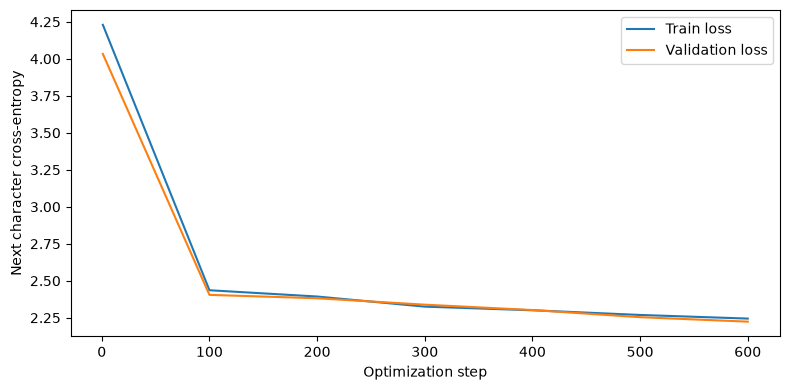

In [5]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.plot([r[0] for r in loss_history],[r[1] for r in loss_history],label='Train loss')
plt.plot([r[0] for r in loss_history],[r[2] for r in loss_history],label='Validation loss')
plt.xlabel('Optimization step');plt.ylabel('Next character cross-entropy');plt.legend();plt.tight_layout();plt.show()
